In [198]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection  import train_test_split
from sklearn.linear_model  import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score, precision_score, classification_report

In [199]:
df = pd.read_excel("Student_Depression_Dataset.xlsx")

In [200]:
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No


In [201]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [202]:
df["Depression"] = df["Depression"].map({"Yes": 1, "No": 0})

In [203]:
df.isnull().sum()


Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [204]:
df.duplicated().sum()

np.int64(0)

In [205]:
## clean

In [206]:
df["Depression"].value_counts()

Depression
0    3263
1    1201
Name: count, dtype: int64

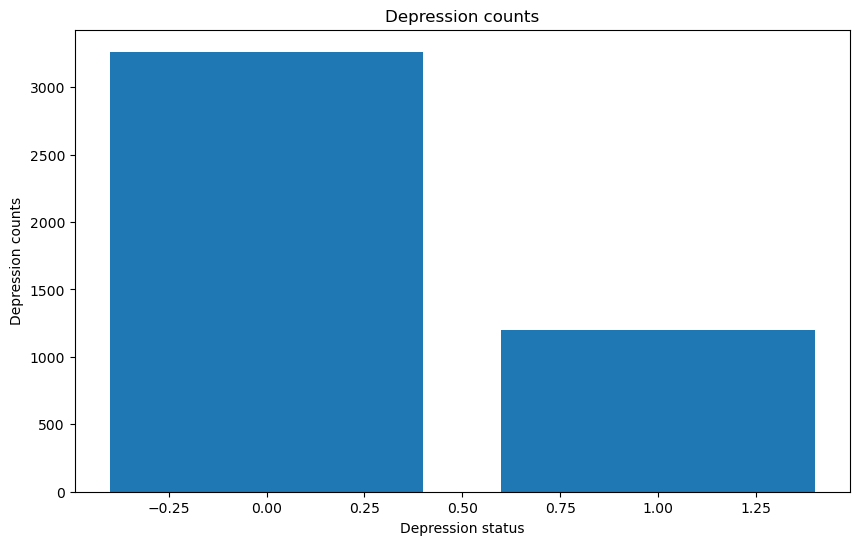

In [207]:
plt.figure(figsize=(10, 6))
plt.bar(df["Depression"].value_counts().index, df["Depression"].value_counts())
plt.title("Depression counts")
plt.ylabel("Depression counts")
plt.xlabel("Depression status")
plt.show()

In [208]:
df_num = df.select_dtypes(include= "int")
df_num.corr()

,Age,Current_semester,Cost_without_study,Depression
Age,1.000000,0.325304,-0.062625,-0.033871
Current_semester,0.325304,1.000000,0.013762,-0.017801
Cost_without_study,-0.062625,0.013762,1.000000,0.018222
Depression,-0.033871,-0.017801,0.018222,1.000000


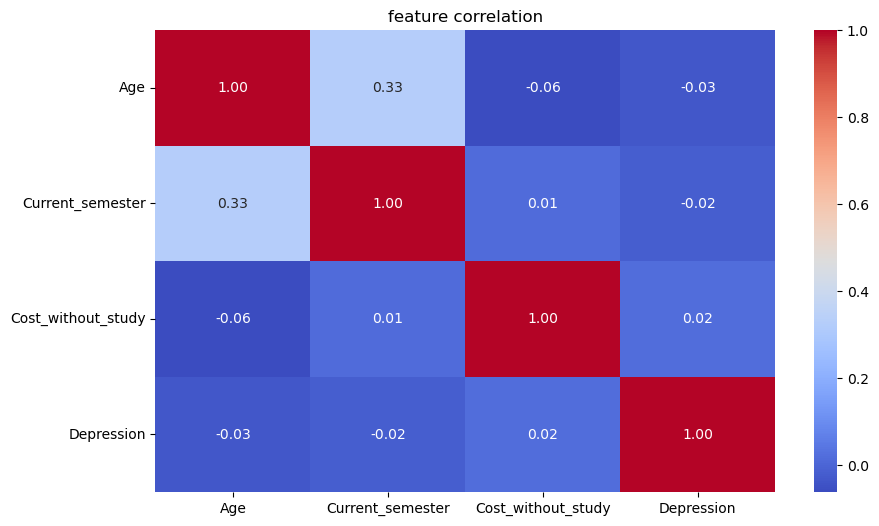

In [209]:
plt.figure(figsize= (10,6))
sns.heatmap(df_num.corr(), cmap= "coolwarm", annot= True, fmt= ".2f")
plt.title("feature correlation")
plt.show()

### Logistic Regression

In [210]:
X = df.drop(columns=["Depression"])
y = df["Depression"]

In [211]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify= y, random_state= 42)

In [212]:
model= LogisticRegression(max_iter=1000)

In [213]:
numerical_cols= X.select_dtypes(include= "int").columns
categorical_cols= X.select_dtypes(include= "object").columns

In [214]:
standardscaler= StandardScaler()
encoder= OneHotEncoder(drop="first", handle_unknown="ignore")

In [215]:
preprocessing = ColumnTransformer(transformers=[
    ("nums", standardscaler, numerical_cols),
    ("cats", encoder, categorical_cols)
    ])

In [216]:
Logistic_pipeline= Pipeline(steps=[
    ("preprocessing",preprocessing),
    ("model", model)
    ])

In [217]:
Logistic_pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('nums', ...), ('cats', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [225]:
y_pred= Logistic_pipeline.predict(X_test)
y_pred[[0]]

array([0])

In [227]:
# Check for Accurracy 
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.2f}")

# Confusion matrix 
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Confusion Matrix\n{conf_matrix}")

# Classification Report 
c_report = classification_report(y_test, y_pred)
print(f"Classification Report:\n {c_report}")

Accuracy Score: 0.97
Confusion Matrix
[[646   7]
 [ 21 219]]
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98       653
           1       0.97      0.91      0.94       240

    accuracy                           0.97       893
   macro avg       0.97      0.95      0.96       893
weighted avg       0.97      0.97      0.97       893

